# 12 · Booking segments (clustering)

**Task:** P4-06 · **Owner:** M1 · Mahdhi S.M.M (IT24100667)

**Goal:** Put similar bookings into a small number of groups (clusters). Then describe each group and give it a name, so the hotel can make one rule per group instead of one rule per booking.

**Input:** `data/processed/shared_prepared/` (train, val, test)
**Output:** segment labels for every booking (with `booking_id`) in `data/processed/clusters/`, and the fitted model in `models/`

## Summary (results of this notebook)



| Item | Result |
|---|---|
| Method | **K-Means** (compared with K-Prototypes) |
| Number of segments (k) | **3** |
| Features | 11 (5 numbers, 6 categories) |
| Silhouette (k = 3, sample of 10,000 train bookings) | 0.141 (low: the segments overlap) |
| Bookings with a segment | train 58,192 · val 10,458 · test 17,324 |


| Segment | Share of train | Typical booking (median) | Cancel rate | Avg booking value | Share of lost value |
|---|---|---|---|---|---|
| 1 · Short solo stays | 18.8% | 1 adult, 1 night, booked 10 days before | 17.4% | 173.3 | 6.3% |
| 2 · Short stays for two | 43.6% | 2 adults, 2 nights, booked 23 days before | 24.4% | 232.8 | 25.1% |
| 3 · Long planned holidays | 37.6% | 2 adults, 2 weekend + 4 week nights, booked 90 days before | 30.4% | 599.5 | 68.6% |

**Main result:** Long planned holidays are 37.6% of train bookings, but **68.6% of the money lost to cancellations**.

## What is clustering, and why do we need it?

Our classifiers give **one risk number per booking**. That tells the manager *which* booking is risky. It does not tell the manager *what kind* of booking is risky.

Clustering groups bookings that look alike. Then we can say: *"Group A is 30% of all bookings, and 40% of them cancel."* A manager can make a rule for a group.

## Setup
**What we do:** Import the libraries and set the folder paths.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from kmodes.kprototypes import KPrototypes

pd.set_option("display.max_columns", None)

RANDOM_STATE = 42  # team rule: 42 everywhere

In [ ]:
# Find the project folder.
# This works if the notebook runs from the project folder or from notebooks/
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed" / "shared_prepared"  # input
OUT_DIR = ROOT / "data" / "processed" / "clusters"         # output: labels
MODEL_DIR = ROOT / "models"                                  # output: model

print("Project folder:", ROOT)

Project folder: c:\Users\ACER\Mahdhi\SLIIT\Y3S1\ML\Project\hotel-cancellation


## Step 1 · Load the data

**What we do:** Load the train, val and test files made in `07_shared_prep` (M2).

**Why:** These files are already cleaned and have the 5 new features from `06_feature_engineering` (M3). **Every booking has a `booking_id`**, so later we can join our segments with the risk scores from the classifiers.

In [ ]:
train = pd.read_csv(DATA_DIR / "hotel_train_prepared.csv")
val = pd.read_csv(DATA_DIR / "hotel_val_prepared.csv")
test = pd.read_csv(DATA_DIR / "hotel_test_prepared.csv")

print("Train:", train.shape)
print("Val:  ", val.shape)
print("Test: ", test.shape)

Train: (58192, 29)
Val:   (10458, 29)
Test:  (17324, 29)


In [ ]:
# Check: booking_id must be unique, so the join in notebook 14 works
print("booking_id unique in train:", train["booking_id"].is_unique)
print("booking_id unique in val:  ", val["booking_id"].is_unique)
print("booking_id unique in test: ", test["booking_id"].is_unique)

booking_id unique in train: True
booking_id unique in val:   True
booking_id unique in test:  True


**What we found:** Train has 58,192 bookings, val has 10,458 and test has 17,324. All three files have the same 29 columns. **`booking_id` is unique in all three files**, so the join in notebook 14 will work.

## Step 2 · Choose the features

**What we do:** We start from the 11 candidate features chosen in `04_eda_multivariate` (Decision Log D-11). We make **3 small changes**, and we show the reason for each one below.

**Why:** K-Means puts two bookings in the same cluster when their distance is small. **Every feature adds to the distance**, so every feature we choose changes the clusters.

**why two similar features count twice**
Imagine we have `price_in_rupees` and `price_in_dollars`. They say the same thing. If we use both, the price is counted **two times** in the distance, and the other features matter less. So we avoid features that repeat the same information.

In [ ]:
# Evidence for change 1: children -> has_kids
zero_children = (train["children"] == 0).mean() * 100
print("Bookings with 0 children:", round(zero_children, 1), "%")
print()
print("has_kids values (0 = no kids, 1 = has kids):")
print(train["has_kids"].value_counts())

Bookings with 0 children: 91.4 %

has_kids values (0 = no kids, 1 = has kids):
has_kids
0    52637
1     5555
Name: count, dtype: int64


In [ ]:
# Evidence for change 2: arrival_date_month -> season
print("Different values in arrival_date_month:", train["arrival_date_month"].nunique())
print("Different values in season:            ", train["season"].nunique())

Different values in arrival_date_month: 12
Different values in season:             4


In [ ]:
# Evidence for change 3: keep weekend nights and week nights as 2 features
corr = train["stays_in_weekend_nights"].corr(train["stays_in_week_nights"])
print("Correlation between weekend nights and week nights:", round(corr, 3))

Correlation between weekend nights and week nights: 0.559


**The 3 changes and why:**

1. **`children` → `has_kids` (yes/no).** 91.4% of train bookings have 0 children, so the number is almost always the same. A log does not help with this (notebook 04, Step 5). `has_kids` keeps the useful part as yes/no: 5,555 train bookings (9.5%) have kids.
2. **`arrival_date_month` → `season`.** `arrival_date_month` has 12 values, so one-hot encoding makes 12 columns for one idea (the time of year). `season` has 4 values and keeps the same idea. With fewer columns, the time of year does not take too much of the distance.
3. **Keep `stays_in_weekend_nights` and `stays_in_week_nights` as two features** (we do not use `total_nights`). Their correlation is 0.559. This is moderate: the two features are related, but they are not copies. We keep both, because (our view) **weekend nights vs weekday nights helps to tell different kinds of trips apart**, for example a weekend holiday and a weekday work trip.

**One more choice: `has_kids` is treated as a category, not a number.** It only has two values (0 or 1), like "yes" or "no". If we scale it like a number, the rare value 1 becomes a very big number (around 3), and families would control the whole clustering. As a category it has the same weight as the other categories.

In [ ]:
# Numbers (we will log and scale these in Step 4)
numeric_features = [
    "lead_time",                # days between booking and arrival
    "stays_in_weekend_nights",  # nights on Saturday or Sunday
    "stays_in_week_nights",     # nights from Monday to Friday
    "adults",                   # number of adults
    "adr",                      # average price per night
]

# Categories (we will one-hot encode these for K-Means)
categorical_features = [
    "hotel",               # City Hotel or Resort Hotel
    "season",              # Winter, Spring, Summer, Autumn
    "meal",                # meal package
    "market_segment",      # how the booking was made (Online TA, Groups, ...)
    "reserved_room_type",  # room type booked
    "has_kids",            # 0 = no kids, 1 = has kids
]

features = numeric_features + categorical_features
print(len(features), "features:", features)

# Safety check: the answer must NOT be a clustering feature
print("is_canceled used as a feature?", "is_canceled" in features)

11 features: ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'adr', 'hotel', 'season', 'meal', 'market_segment', 'reserved_room_type', 'has_kids']
is_canceled used as a feature? False


## Step 3 · Handle outliers in `adr` and `adults`

**What we do:** We set a maximum value for `adr` (price per night) and `adults`. Any value above the maximum is changed to the maximum. A price below 0 is changed to 0.

**Why:** One train booking has a price of 5,400, and one has 55 adults. **Outliers change the clusters a lot**, because distance gets very big for that one booking. We take the maximum values **from train only**, and use the same values for val and test.

In [ ]:
# Look at the outliers first
print("Train adr:    min =", train["adr"].min(), " max =", train["adr"].max())
print("Train adults: min =", train["adults"].min(), " max =", train["adults"].max())
print()
print("Val adr:      min =", val["adr"].min(), " max =", val["adr"].max())
print("Test adr:     min =", test["adr"].min(), " max =", test["adr"].max())

Train adr:    min = 0.0  max = 5400.0
Train adults: min = 1  max = 55

Val adr:      min = -6.38  max = 336.0
Test adr:     min = 0.0  max = 510.0


In [ ]:
# Maximum for adr: 99% of train prices are below this value
adr_max = train["adr"].quantile(0.99)

# Maximum for adults: 4 (our choice, see the evidence below)
adults_max = 4

print("adr maximum:", round(adr_max, 2))
print("Train bookings with adr above the maximum:", (train["adr"] > adr_max).sum())
print()
print("adults maximum:", adults_max)
print("Train bookings with more than 4 adults:", (train["adults"] > adults_max).sum())
print("Val bookings with more than 4 adults:  ", (val["adults"] > adults_max).sum())
print("Test bookings with more than 4 adults: ", (test["adults"] > adults_max).sum())

adr maximum: 241.51
Train bookings with adr above the maximum: 582

adults maximum: 4
Train bookings with more than 4 adults: 16
Val bookings with more than 4 adults:   0
Test bookings with more than 4 adults:  0


In [ ]:
# Bookings with price 0: are they errors or free stays?
free = train[train["adr"] == 0]
print("Train bookings with adr = 0:", len(free))
print()
print("Their market_segment:")
print(free["market_segment"].value_counts())

Train bookings with adr = 0: 813

Their market_segment:
market_segment
Complementary    457
Groups           151
Offline TA/TO    108
Direct            57
Online TA         27
Corporate         13
Name: count, dtype: int64


**What we found:** 

- The maximum for `adr` is **241.51**. This changes 582 train bookings (1% of train). Val and test have prices above it too (up to 336 and 510), and they get the same maximum.
- Only **16** train bookings have more than 4 adults, and val and test have none. So the maximum of 4 changes very little.
- Train has no price below 0. Val has one (−6.38), and it becomes 0.
- The **813** train bookings with `adr` = 0 are **kept**. 457 of them are in the Complementary segment (free stays given by the hotel), so most of them look like real free stays, not errors.

In [ ]:
def limit_outliers(df):
    # Make a copy, so the original data does not change
    df = df.copy()
    # Prices below 0 become 0, prices above adr_max become adr_max
    df["adr"] = df["adr"].clip(lower=0, upper=adr_max)
    # More than adults_max adults becomes adults_max
    df["adults"] = df["adults"].clip(upper=adults_max)
    return df


# Same rule for all three files (the maximum values came from train)
train_clean = limit_outliers(train)
val_clean = limit_outliers(val)
test_clean = limit_outliers(test)

print("Train adr after:", train_clean["adr"].min(), "to", round(train_clean["adr"].max(), 2))
print("Train adults after:", train_clean["adults"].min(), "to", train_clean["adults"].max())

Train adr after: 0.0 to 241.51
Train adults after: 1 to 4


## Step 4 · Log and scaling

**What we do:**
1. **Log:** we apply `log(1 + x)` to 4 number features: `lead_time`, `stays_in_weekend_nights`, `stays_in_week_nights`, `adults`. **Not to `adr`** (the reason is in the check below).
2. **Scaling:** we change each number feature so its mean is 0 and its standard deviation is 1 (`StandardScaler`).


**why log first**

`lead_time` and the night features are **skewed**: most values are small, and a few are very big. Without log, a few very big values take most of the scale. `log(1 + x)` makes big values smaller much more than small values: log(1 + 9) = 2.3, but log(1 + 999) = 6.9. We use `log(1 + x)` and not `log(x)` because many values are 0, and log(0) does not exist.

In `04_eda_multivariate` Step 5, the log made the skew of 4 features much smaller (for example `lead_time`: 1.43 → −0.72). Notebook 04 also planned a log for `adr`. We check this again here, because Step 3 changed `adr`.

In [ ]:
# Skew of adr AFTER Step 3 (the maximum), with and without log
# Skew near 0 = balanced. Skew above 1 or below -1 = strongly skewed.
print("Skew of adr after the maximum:          ", round(train_clean["adr"].skew(), 2))
print("Skew of adr after the maximum and log:  ", round(np.log1p(train_clean["adr"]).skew(), 2))

Skew of adr after the maximum:           0.74
Skew of adr after the maximum and log:   -3.6


**What we found:** After the maximum in Step 3, `adr` has a skew of only **0.74**, so it is no longer strongly skewed. With a log, the skew becomes **−3.6**, which is worse: the free bookings (`adr` = 0) move very far away from all other bookings. **So `adr` gets scaling only, no log.** This changes one part of the plan from notebook 04 (D-11). The reason: Step 3 removed the very big prices that made `adr` skewed.

In [ ]:
# Number features that get log + scaling
log_features = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
]

# Number features that get scaling only (no log)
scale_only_features = ["adr"]

# Log first, then scaling
log_and_scale = Pipeline([
    ("log", FunctionTransformer(np.log1p)),  # log(1 + x)
    ("scale", StandardScaler()),             # mean 0, standard deviation 1
])

# All number steps together
number_prep = ColumnTransformer([
    ("log_and_scale", log_and_scale, log_features),
    ("scale_only", StandardScaler(), scale_only_features),
])

# Look at the result on train (only to check it works)
numbers_after = number_prep.fit_transform(train_clean[numeric_features])
numbers_after = pd.DataFrame(numbers_after, columns=log_features + scale_only_features)
numbers_after.describe().round(2)

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,adr
count,58192.00,58192.00,58192.00,58192.00,58192.00
mean,0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.07,-1.11,-2.18,-1.84,-2.15
25%,-0.66,-1.11,-0.86,0.34,-0.69
50%,0.22,0.26,-0.09,0.34,-0.17
75%,0.80,1.06,0.46,0.34,0.55
max,1.95,4.48,4.88,3.09,3.11


**What we found:** All 5 number features now have mean 0 and standard deviation 1. The values are between about −2.2 and 4.9, so **no feature is much bigger than the others**. The free bookings (`adr` = 0) are at −2.15, close to the other bookings.

## Step 5 · K-Means

**What we do:** We try K-Means with k = 2, 3, 4, 5, 6, 7 and 8 clusters, and measure two scores for each k.

**Why:** We do not know the best number of clusters. **We try many and compare them.**

**Two practical choices:**
- **K-Means needs numbers**, so the categories are one-hot encoded (one 0/1 column for each category value).
- **We search for k on a sample of 10,000 train bookings.** This is faster (silhouette compares every pair of bookings) and gives the same picture. The final model in Step 8 uses all train bookings.

In [ ]:
# Prepare the data for K-Means:
# numbers -> log + scaling, categories -> one-hot encoding
kmeans_prep = ColumnTransformer([
    ("log_and_scale", log_and_scale, log_features),
    ("scale_only", StandardScaler(), scale_only_features),
    ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

# A sample of 10,000 train bookings for the search
search_data = train_clean.sample(10000, random_state=RANDOM_STATE)

# Prepare the sample once (faster than inside the loop)
X_search = kmeans_prep.fit_transform(search_data)
print("Rows and columns after one-hot encoding:", X_search.shape)

Rows and columns after one-hot encoding: (10000, 33)


**Note:** Each booking now has 33 columns: 5 numbers + 28 one-hot columns. (Room type L has only 6 train bookings, so it is not in this sample. The final model in Step 8 uses all train bookings and has 34 columns.) **Most columns come from categories**, so categories have a big part of the distance. This is one reason we also try K-Prototypes in Step 6.

In [ ]:
k_values = [2, 3, 4, 5, 6, 7, 8]

kmeans_inertia = []     # elbow score for each k
kmeans_silhouette = []  # silhouette score for each k
kmeans_smallest = []    # size of the smallest cluster (% of bookings) for each k

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_search)

    kmeans_inertia.append(model.inertia_)
    kmeans_silhouette.append(silhouette_score(X_search, labels))

    smallest = pd.Series(labels).value_counts(normalize=True).min() * 100
    kmeans_smallest.append(smallest)

kmeans_results = pd.DataFrame({
    "k": k_values,
    "inertia": kmeans_inertia,
    "silhouette": kmeans_silhouette,
    "smallest_cluster_%": kmeans_smallest,
})
kmeans_results.round(3)

,k,inertia,silhouette,smallest_cluster_%
0,2,65716.464,0.158,38.13
1,3,59053.977,0.141,18.43
2,4,54358.433,0.135,17.76
3,5,50529.800,0.132,15.22
4,6,47579.838,0.128,12.15
5,7,45630.188,0.132,9.00
6,8,44263.721,0.130,8.64


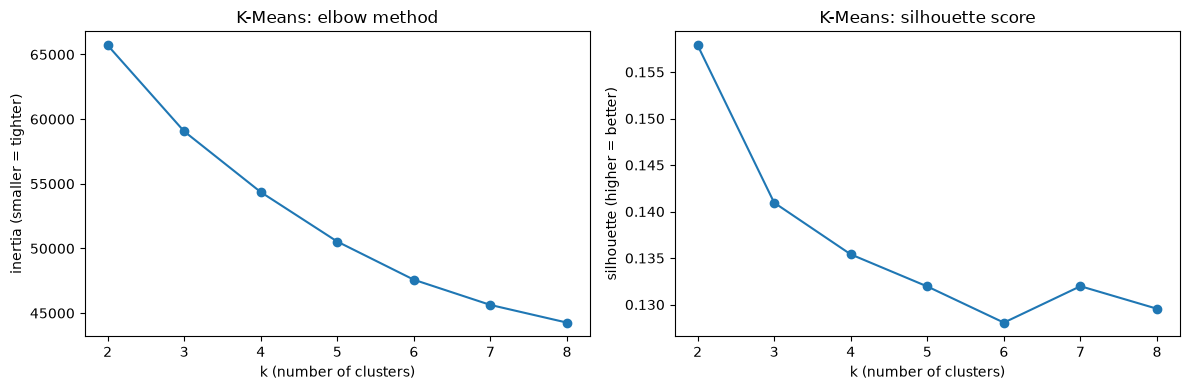

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, kmeans_inertia, marker="o")
axes[0].set_title("K-Means: elbow method")
axes[0].set_xlabel("k (number of clusters)")
axes[0].set_ylabel("inertia (smaller = tighter)")

axes[1].plot(k_values, kmeans_silhouette, marker="o")
axes[1].set_title("K-Means: silhouette score")
axes[1].set_xlabel("k (number of clusters)")
axes[1].set_ylabel("silhouette (higher = better)")

plt.tight_layout()
plt.show()

**What we found:** 

- The silhouette is highest at k = 2 (0.158), then 0.141 at k = 3 and 0.135 at k = 4. **All silhouette values are low (0.13 to 0.16): the clusters overlap, and there are no clearly separate groups.** This matches the pairplot in notebook 04, Step 6.
- The elbow plot has **no clear elbow**. Inertia drops a little less with each new cluster: about 6,700 from k = 2 to 3, 4,700 from 3 to 4, and 3,800 from 4 to 5.
- The smallest cluster is at least 8.6% of bookings for every k.

## Step 6 · K-Prototypes

**What we do:** We try K-Prototypes with the same k values (2 to 8) and the same 10,000 bookings.

**Why:** **6 of our 11 features are categories.** K-Means can only use them after one-hot encoding. K-Prototypes is made for mixed data (numbers and categories together), so it is a fair method to compare with.

**Fair comparison:** we calculate the silhouette for K-Prototypes on the **same prepared data as K-Means** (`X_search`). So both methods are measured with the same ruler.

**Why K-Prototypes is not inside a Pipeline:** the `kmodes` library is not part of scikit-learn. It needs the category columns as text and a list of their positions. So we prepare its data by hand, using the same log and scaling steps as K-Means.

In [ ]:
# Numbers: the same log + scaling as K-Means
numbers_scaled = number_prep.fit_transform(search_data[numeric_features])

# Build one table: scaled numbers first, then the categories as text
kp_data = pd.DataFrame(numbers_scaled, columns=numeric_features)
for col in categorical_features:
    kp_data[col] = search_data[col].astype(str).values

kp_array = kp_data.to_numpy()

# Positions of the category columns (they come after the 5 number columns)
category_positions = list(range(len(numeric_features), len(features)))
print("Category column positions:", category_positions)
kp_data.head()

Category column positions: [5, 6, 7, 8, 9, 10]


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,adr,hotel,season,meal,market_segment,reserved_room_type,has_kids
0,-1.247046,-1.097873,-0.110420,0.347156,0.583676,Resort Hotel,Summer,BB,Online TA,A,0
1,0.865108,0.263534,0.434194,0.347156,0.015789,City Hotel,Summer,BB,Online TA,A,0
2,-1.673382,-1.097873,-0.110420,-1.847586,-1.280215,Resort Hotel,Spring,BB,Corporate,A,0
3,0.294036,1.059907,0.856629,0.347156,0.238148,City Hotel,Spring,SC,Online TA,A,0
4,1.137222,1.059907,1.201784,0.347156,0.947734,Resort Hotel,Summer,FB,Offline TA/TO,A,1


In [ ]:
kproto_cost = []        # elbow score for each k
kproto_silhouette = []  # silhouette score for each k (same ruler as K-Means)
kproto_smallest = []    # size of the smallest cluster (%) for each k

for k in k_values:
    model = KPrototypes(n_clusters=k, init="Cao", n_init=3, random_state=RANDOM_STATE)
    labels = model.fit_predict(kp_array, categorical=category_positions)

    kproto_cost.append(model.cost_)
    kproto_silhouette.append(silhouette_score(X_search, labels))

    smallest = pd.Series(labels).value_counts(normalize=True).min() * 100
    kproto_smallest.append(smallest)

print("gamma chosen by the library (last run):", round(model.gamma, 3))

kproto_results = pd.DataFrame({
    "k": k_values,
    "cost": kproto_cost,
    "silhouette": kproto_silhouette,
    "smallest_cluster_%": kproto_smallest,
})
kproto_results.round(3)

gamma chosen by the library (last run): 0.5


,k,cost,silhouette,smallest_cluster_%
0,2,48156.062,0.155,39.59
1,3,41684.593,0.140,18.46
2,4,37498.765,0.135,17.30
3,5,33993.033,0.128,14.71
4,6,31078.223,0.126,11.25
5,7,29176.849,0.131,9.33
6,8,27873.494,0.128,7.96


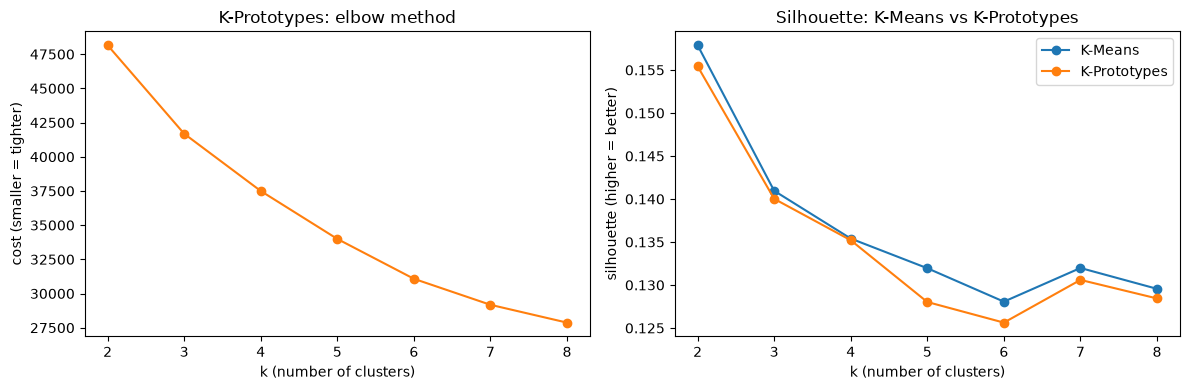

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, kproto_cost, marker="o", color="tab:orange")
axes[0].set_title("K-Prototypes: elbow method")
axes[0].set_xlabel("k (number of clusters)")
axes[0].set_ylabel("cost (smaller = tighter)")

axes[1].plot(k_values, kmeans_silhouette, marker="o", label="K-Means")
axes[1].plot(k_values, kproto_silhouette, marker="o", label="K-Prototypes")
axes[1].set_title("Silhouette: K-Means vs K-Prototypes")
axes[1].set_xlabel("k (number of clusters)")
axes[1].set_ylabel("silhouette (higher = better)")
axes[1].legend()

plt.tight_layout()
plt.show()

**What we found:** 

- K-Prototypes gives **almost the same silhouette as K-Means** for every k: 0.140 vs 0.141 at k = 3, and 0.135 vs 0.135 at k = 4.
- The cluster sizes are also very close (k = 3: smallest cluster 18.46% vs 18.43%). Our interpretation: the two methods find similar groups.
- Gamma = 0.5. The cost elbow is smooth too, with no clear elbow.

## Step 7 · Choose the method and k

**What we do:** We put both methods in one table and choose with **3 rules that we wrote before looking at the table**:

1. **k from 3 to 6.** A manager cannot use 2 groups (too simple) or 7+ groups (too many to remember).
2. **The smallest cluster has at least 5% of bookings.** A very small cluster is not useful for a hotel rule.
3. From the options left, choose the **highest silhouette**. If two options are very close (difference below 0.01), choose the simpler one (fewer clusters, or K-Means).

**Why:** Clear rules make the choice fair and easy to check. We also look at the elbow plots as a second check.

In [ ]:
# Put both methods in one table
kmeans_table = kmeans_results[["k", "silhouette", "smallest_cluster_%"]].copy()
kmeans_table["method"] = "K-Means"

kproto_table = kproto_results[["k", "silhouette", "smallest_cluster_%"]].copy()
kproto_table["method"] = "K-Prototypes"

all_results = pd.concat([kmeans_table, kproto_table], ignore_index=True)

# Rule 1 and rule 2
all_results["k_3_to_6"] = all_results["k"].between(3, 6)
all_results["smallest_5%_or_more"] = all_results["smallest_cluster_%"] >= 5
all_results["passes_rules"] = all_results["k_3_to_6"] & all_results["smallest_5%_or_more"]

all_results.sort_values("silhouette", ascending=False).round(3)

,k,silhouette,smallest_cluster_%,method,k_3_to_6,smallest_5%_or_more,passes_rules
0,2,0.158,38.13,K-Means,False,True,False
7,2,0.155,39.59,K-Prototypes,False,True,False
1,3,0.141,18.43,K-Means,True,True,True
8,3,0.140,18.46,K-Prototypes,True,True,True
2,4,0.135,17.76,K-Means,True,True,True
9,4,0.135,17.30,K-Prototypes,True,True,True
5,7,0.132,9.00,K-Means,False,True,False
3,5,0.132,15.22,K-Means,True,True,True
12,7,0.131,9.33,K-Prototypes,False,True,False
6,8,0.130,8.64,K-Means,False,True,False


In [ ]:
# Rule 3: from the options that pass, highest silhouette first
passing = all_results[all_results["passes_rules"]].sort_values("silhouette", ascending=False)
passing.round(3)

,k,silhouette,smallest_cluster_%,method,k_3_to_6,smallest_5%_or_more,passes_rules
1,3,0.141,18.43,K-Means,True,True,True
8,3,0.140,18.46,K-Prototypes,True,True,True
2,4,0.135,17.76,K-Means,True,True,True
9,4,0.135,17.30,K-Prototypes,True,True,True
3,5,0.132,15.22,K-Means,True,True,True
4,6,0.128,12.15,K-Means,True,True,True
10,5,0.128,14.71,K-Prototypes,True,True,True
11,6,0.126,11.25,K-Prototypes,True,True,True


**What we found:** 

- Rules 1 and 2 leave 8 options (k = 3 to 6, for both methods).
- The highest silhouette is **K-Means with k = 3 (0.141)**. K-Prototypes with k = 3 (0.140) and both methods with k = 4 (0.135) are within 0.01, so rule 3 also points to the simpler option.
- **Choice: K-Means with k = 3.** K-Means is also easier to use later: it fits into a scikit-learn Pipeline, so one saved object can give a segment to a new booking.
- Note: k = 2 has the highest silhouette of all (0.158), but rule 1 removes it, because 2 groups are too simple for a deposit policy.

## Step 8 · Final model: fit on train, give a segment to every booking

**What we do:** We put the preparation and K-Means (k = 3) into **one Pipeline**. We fit it on **all train bookings**. Then we give a segment to every booking in train, val and test.

**Why:** The Pipeline learns everything (log, scaling, one-hot, centres) **from train only**. Val and test only receive labels with "nearest centre wins". So no information from val or test goes into the model.

**Segment numbers:** K-Means gives the clusters the numbers 0, 1, 2 in a random order. We change them to 1, 2, 3, **ordered by average `lead_time`** (1 = booked closest to arrival). So the numbers always mean the same thing, even if the code runs on another computer.

In [ ]:
final_k = 3

final_model = Pipeline([
    ("prep", kmeans_prep),
    ("kmeans", KMeans(n_clusters=final_k, n_init=10, random_state=RANDOM_STATE)),
])

# Fit on ALL train bookings (not the 10,000 sample)
final_model.fit(train_clean)

# Cluster numbers from K-Means (0, 1, 2)
train_raw = final_model.predict(train_clean)
val_raw = final_model.predict(val_clean)
test_raw = final_model.predict(test_clean)

In [ ]:
# Order the clusters by average lead_time (smallest first)
mean_lead_time = train_clean["lead_time"].groupby(train_raw).mean().sort_values()
print("Average lead_time for each K-Means cluster:")
print(mean_lead_time.round(1))

# Old number -> new number (1, 2, 3)
segment_number = {}
new = 1
for old in mean_lead_time.index:
    segment_number[old] = new
    new = new + 1
print()
print("Old number -> new number:", segment_number)

# Add the new segment number to each file
train_clean["segment"] = pd.Series(train_raw).map(segment_number).values
val_clean["segment"] = pd.Series(val_raw).map(segment_number).values
test_clean["segment"] = pd.Series(test_raw).map(segment_number).values

print()
print("Train bookings in each segment:")
print(train_clean["segment"].value_counts().sort_index())

Average lead_time for each K-Means cluster:
0     42.1
1     49.5
2    109.8
Name: lead_time, dtype: float64

Old number -> new number: {0: 1, 1: 2, 2: 3}

Train bookings in each segment:
segment
1    10918
2    25393
3    21881
Name: count, dtype: int64


## Step 9 · Profile and name the segments

**What we do:** For each segment we look at the typical values (median for numbers, percentages for categories). Then we give each segment a short name.

**Why:** "Segment 2" means nothing to a manager. **A profile and a name turn a cluster into something a manager can use.**

We look at `is_canceled` **only in Step 10, after the names are given.** So the names describe the bookings, and are not influenced by the cancel rate.

In [ ]:
# Numbers: median for each segment
profile = train_clean.groupby("segment").agg(
    bookings=("booking_id", "count"),
    lead_time=("lead_time", "median"),
    weekend_nights=("stays_in_weekend_nights", "median"),
    week_nights=("stays_in_week_nights", "median"),
    adults=("adults", "median"),
    adr=("adr", "median"),
    has_kids_pct=("has_kids", "mean"),
)

profile["share_%"] = profile["bookings"] / len(train_clean) * 100
profile["has_kids_pct"] = profile["has_kids_pct"] * 100

profile.round(1)

,bookings,lead_time,weekend_nights,week_nights,adults,adr,has_kids_pct,share_%
segment,,,,,,,,
1,10918,10.0,0.0,1.0,1.0,72.9,1.6,18.8
2,25393,23.0,0.0,2.0,2.0,97.0,11.2,43.6
3,21881,90.0,2.0,4.0,2.0,94.5,11.6,37.6


In [ ]:
# Categories: what % of each segment has each value (each row adds up to 100%)
for col in ["hotel", "season", "market_segment", "meal", "reserved_room_type"]:
    table = pd.crosstab(train_clean["segment"], train_clean[col], normalize="index") * 100
    print("====", col, "(% of each segment) ====")
    display(table.round(1))

==== hotel (% of each segment) ====


hotel,City Hotel,Resort Hotel
segment,,
1,66.2,33.8
2,67.3,32.7
3,49.0,51.0


==== season (% of each segment) ====


season,Autumn,Spring,Summer,Winter
segment,,,,
1,37.5,20.4,13.6,28.4
2,29.9,19.2,25.1,25.7
3,30.0,18.6,35.6,15.8


==== market_segment (% of each segment) ====


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA
segment,,,,,,,
1,1.0,2.1,21.8,13.3,11.8,16.9,33.1
2,0.0,1.1,2.0,16.2,5.0,12.0,63.8
3,0.1,0.0,0.5,10.2,4.8,24.9,59.5


==== meal (% of each segment) ====


meal,BB,FB,HB,SC,Undefined
segment,,,,,
1,86.7,0.3,5.4,6.7,0.9
2,79.6,0.3,6.8,13.0,0.3
3,76.9,0.7,15.8,5.9,0.7


==== reserved_room_type (% of each segment) ====


reserved_room_type,A,B,C,D,E,F,G,H,L
segment,,,,,,,,,
1,88.3,0.4,0.2,7.2,2.8,0.7,0.4,0.1,0.0
2,66.6,1.3,0.7,18.8,5.5,4.0,2.3,0.9,0.0
3,56.5,1.3,1.2,24.5,9.3,3.5,3.0,0.8,0.0


**What we found:**



- **Segment 1 (18.8% of train):** median 1 adult, 1 week night, 0 weekend nights, booked 10 days before arrival, price 72.9 per night. 66.2% City Hotel. It has the most Corporate bookings (21.8%, compared with 2.0% and 0.5% in the other segments). Only 1.6% have kids. 88.3% book room type A.
- **Segment 2 (43.6%):** median 2 adults, 2 week nights, 0 weekend nights, booked 23 days before, price 97.0. 67.3% City Hotel. 63.8% come from Online TA.
- **Segment 3 (37.6%):** median 2 adults, 2 weekend nights + 4 week nights, booked 90 days before, price 94.5. 51.0% Resort Hotel. It has the most Summer arrivals (35.6%), the most Offline TA/TO bookings (24.9%) and the most half board meals (HB, 15.8%).

**Names** (our interpretation of the tables above):

1. **Short solo stays:** 1 adult, 1 night, booked 10 days before.
2. **Short stays for two:** 2 adults, 2 week nights, booked 23 days before.
3. **Long planned holidays:** booked 90 days before, the longest stays, the most Resort Hotel and Summer bookings.

In [ ]:
segment_names = {
    1: "Short solo stays",
    2: "Short stays for two",
    3: "Long planned holidays",
}

train_clean["segment_name"] = train_clean["segment"].map(segment_names)
val_clean["segment_name"] = val_clean["segment"].map(segment_names)
test_clean["segment_name"] = test_clean["segment"].map(segment_names)

train_clean["segment_name"].value_counts()

segment_name
Short stays for two      25393
Long planned holidays    21881
Short solo stays         10918
Name: count, dtype: int64

### A picture of the segments (PCA)

**What we do:** We draw every booking as a dot, coloured by its segment.

**Why:** After one-hot encoding, each train booking has 34 numbers. We cannot draw 34 dimensions. **PCA makes 2 new features that keep as much of the spread as possible**, so we can draw a normal 2D picture.


In [ ]:
# The prepared train data, from the fitted Pipeline
X_train_prepared = final_model.named_steps["prep"].transform(train_clean)
print("Numbers per booking after preparation:", X_train_prepared.shape[1])

pca = PCA(n_components=2, random_state=RANDOM_STATE)
points = pca.fit_transform(X_train_prepared)

print("Spread kept by PC1 and PC2:", pca.explained_variance_ratio_.round(3))
print("Total spread kept:", round(pca.explained_variance_ratio_.sum(), 3))

Numbers per booking after preparation: 34
Spread kept by PC1 and PC2: [0.245 0.162]
Total spread kept: 0.407


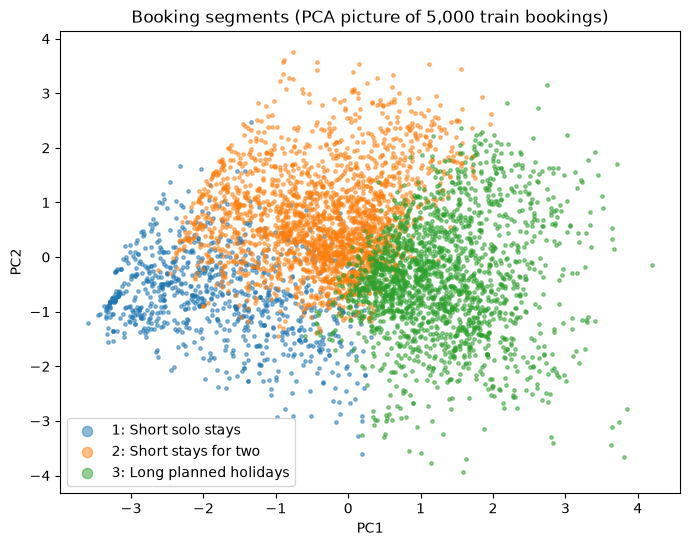

In [ ]:
# Draw 5,000 bookings (all 58,000 would hide each other)
plot_rows = np.random.RandomState(RANDOM_STATE).choice(len(points), 5000, replace=False)

plt.figure(figsize=(8, 6))
for number in [1, 2, 3]:
    rows = plot_rows[train_clean["segment"].values[plot_rows] == number]
    plt.scatter(points[rows, 0], points[rows, 1], s=6, alpha=0.5,
                label=f"{number}: {segment_names[number]}")

plt.title("Booking segments (PCA picture of 5,000 train bookings)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(markerscale=3)
plt.show()

**What we found:** 

- PC1 and PC2 keep **40.7%** of the spread (24.5% + 16.2%), so the picture shows only part of the full data.
- Segment 1 is mostly on the left, segment 3 on the right, and segment 2 in the middle and top.
- **The segments touch and overlap at their edges**, and there are no separate islands. This matches the low silhouette (0.141).

## Step 10 · Cancel rate and booking value per segment (train only)

**What we do:** Now, **after** the segments are made and named, we look at `is_canceled`. For each segment we calculate:
- **cancel rate:** % of bookings that cancelled
- **average booking value:** `adr` × `total_nights` (the money one booking brings)
- **lost value:** the value of the bookings that cancelled, and its share of all lost value

**Why:** **This is the bridge to notebook 14** (Phase 6). There, we join these segments with the risk scores from the final classifier and choose the deposit rule.

We use **train only**. The test set stays locked until Phase 5.

**Note:** `adr` here is the version from Step 3 (maximum 241.51 per night), so one very big price does not change the averages.

In [ ]:
# Money for each booking = price per night x number of nights
train_clean["booking_value"] = train_clean["adr"] * train_clean["total_nights"]

# Money lost = booking value, but only for bookings that cancelled
train_clean["lost_value"] = train_clean["booking_value"] * train_clean["is_canceled"]

risk_table = train_clean.groupby(["segment", "segment_name"]).agg(
    bookings=("booking_id", "count"),
    cancel_rate_pct=("is_canceled", "mean"),
    avg_booking_value=("booking_value", "mean"),
    lost_value=("lost_value", "sum"),
)

risk_table["share_of_bookings_%"] = risk_table["bookings"] / len(train_clean) * 100
risk_table["cancel_rate_pct"] = risk_table["cancel_rate_pct"] * 100
risk_table["share_of_lost_value_%"] = risk_table["lost_value"] / risk_table["lost_value"].sum() * 100

print("Cancel rate of ALL train bookings:", round(train_clean["is_canceled"].mean() * 100, 1), "%")
risk_table.round(1)

Cancel rate of ALL train bookings: 25.3 %


,,bookings,cancel_rate_pct,avg_booking_value,lost_value,share_of_bookings_%,share_of_lost_value_%
segment,segment_name,,,,,,
1,Short solo stays,10918,17.4,173.3,398833.4,18.8,6.3
2,Short stays for two,25393,24.4,232.8,1584151.9,43.6,25.1
3,Long planned holidays,21881,30.4,599.5,4336762.6,37.6,68.6


**What we found:** 

- All train bookings together cancel at **25.3%**.
- **The cancel rate and the booking value both go up from segment 1 to segment 3:**
  - Short solo stays: 17.4% cancel, average value 173.3
  - Short stays for two: 24.4% cancel, average value 232.8
  - Long planned holidays: 30.4% cancel, average value 599.5
- **Long planned holidays are 37.6% of bookings, but 68.6% of all lost value.** They cancel more often, and each booking is worth 2.6 to 3.5 times more than in the other segments.
- Our interpretation: Long planned holidays are the main group to look at for a deposit rule in notebook 14.

## Step 11 · Are the segments stable over time?

**What we do:** We compare the share of each segment in train, val and test. We only count bookings here. We do **not** look at `is_canceled` in val or test.

**Why:** Our split is by **time** (D-4): train is older bookings, test is the newest. **If the shares change a lot, the segments may not describe future bookings well.**

In [ ]:
shares = pd.DataFrame({
    "train_%": train_clean["segment_name"].value_counts(normalize=True) * 100,
    "val_%": val_clean["segment_name"].value_counts(normalize=True) * 100,
    "test_%": test_clean["segment_name"].value_counts(normalize=True) * 100,
})

# Show the segments in order 1, 2, 3
shares = shares.loc[[segment_names[1], segment_names[2], segment_names[3]]]
shares.round(1)

,train_%,val_%,test_%
segment_name,,,
Short solo stays,18.8,18.2,11.2
Short stays for two,43.6,43.1,40.4
Long planned holidays,37.6,38.7,48.4


In [ ]:
# Which arrival months are in each file?
print("Train months:", train["arrival_date_month"].nunique(), "different months")
print("Test months: ", sorted(test["arrival_date_month"].unique()))

Train months: 12 different months
Test months:  ['August', 'July', 'June', 'May']


**What we found:** 

- Train and val shares are almost the same (the differences are 1.1 points or less).
- In test, **Long planned holidays grow from 37.6% to 48.4%**, and Short solo stays drop from 18.8% to 11.2%.
- Test only has arrivals in May, June, July and August (summer). Segment 3 has the most Summer arrivals (Step 9).
- Our interpretation: the change most likely comes from the season, not from a problem in the model. But it shows that **the segment shares depend on the time of year**, so the hotel should check them again in other seasons.

## Step 12 · Save the results

**What we do:**
1. Save the segment of every booking (with `booking_id`) to `data/processed/clusters/`.
2. Save the fitted model to `models/clustering_kmeans.joblib`, together with the outlier maximums, the segment numbers and the names.

**Why:** Notebook 14 joins these files with the risk scores **using `booking_id`**. The saved model can give a segment to a brand-new booking (the demo cell in P7-09).

In [ ]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

train_clean[["booking_id", "segment", "segment_name"]].to_csv(OUT_DIR / "segments_train.csv", index=False)
val_clean[["booking_id", "segment", "segment_name"]].to_csv(OUT_DIR / "segments_val.csv", index=False)
test_clean[["booking_id", "segment", "segment_name"]].to_csv(OUT_DIR / "segments_test.csv", index=False)

print("Saved to:", OUT_DIR)

Saved to: c:\Users\ACER\Mahdhi\SLIIT\Y3S1\ML\Project\hotel-cancellation\data\processed\clusters


In [ ]:
# Everything needed to give a segment to a new booking, in one object
clustering_model = {
    "pipeline": final_model,          # preparation + K-Means, fitted on train
    "adr_max": adr_max,               # Step 3
    "adults_max": adults_max,         # Step 3
    "segment_number": segment_number, # K-Means number -> segment number (Step 8)
    "segment_names": segment_names,   # segment number -> name (Step 9)
    "features": features,             # the 11 features (Step 2)
}

MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(clustering_model, MODEL_DIR / "clustering_kmeans.joblib")
print("Saved to:", MODEL_DIR / "clustering_kmeans.joblib")

Saved to: c:\Users\ACER\Mahdhi\SLIIT\Y3S1\ML\Project\hotel-cancellation\models\clustering_kmeans.joblib


**Check:** load the saved model and give a segment to one test booking, in the same way notebook 14 will do it.

In [ ]:
saved = joblib.load(MODEL_DIR / "clustering_kmeans.joblib")

# One booking from the test file (the original values, before Step 3)
one_booking = test.head(1).copy()

# Step 3 rules, with the saved maximums
one_booking["adr"] = one_booking["adr"].clip(lower=0, upper=saved["adr_max"])
one_booking["adults"] = one_booking["adults"].clip(upper=saved["adults_max"])

raw_number = saved["pipeline"].predict(one_booking)[0]
number = saved["segment_number"][raw_number]

print("booking_id:", one_booking["booking_id"].iloc[0])
print("Segment:", number, "-", saved["segment_names"][number])
print("Same as the saved file?", number == test_clean["segment"].iloc[0])

booking_id: 11312
Segment: 2 - Short stays for two
Same as the saved file? True
